# Online Shopping Purchase Prediction — Practice

**Task:** Predict whether an e-commerce browsing session ends in a purchase (`Revenue`).

Dataset: `online_shoppers_intention.csv`, downloaded from [Kaggle](https://www.kaggle.com/datasets/henrysue/online-shoppers-intention). Use `data_dictionary.csv` for column definitions.

Complete the empty code cells and add your own markdown analysis. The notebook contains no solution code or results. Open `online_shoppers_solution.ipynb` when you want to compare your approach.

Treat this as a take-home project: justify preprocessing, compare the model families, evaluate the minority class, and explain what the results mean for the business.


## 1. Objective and evaluation

Define the prediction unit, positive class and intended use. Choose a primary metric, explain why accuracy alone is insufficient, and describe how you will keep the final test set separate. Discuss when the session features would be available.

## 2. Setup

Import the packages, set a random seed, locate the CSV, and create a figure-export helper. Keep data paths relative so the project runs from this folder. Install the libraries in `requirements.txt` if needed.

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
                              recall_score, f1_score, log_loss, roc_curve,
                              confusion_matrix)


from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


## 3. Load and inspect the data

Load the CSV. Inspect shape, data types, sample rows, missing values, duplicate rows, target balance and value ranges. Decide which integer-coded fields are categorical. Explain whether duplicate profiles should be removed or grouped.

In [14]:
raw = pd.read_csv("online_shoppers_intention.csv")
print(raw.shape)
print(raw.duplicated().sum())
# print(raw.describe())
# print(raw.info())
print(raw["Month"].unique())
# print(raw.head())
raw.head()

(12330, 18)
125
<ArrowStringArray>
['Feb', 'Mar', 'May', 'Oct', 'June', 'Jul', 'Aug', 'Nov', 'Sep', 'Dec']
Length: 10, dtype: str


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [25]:
df = raw.copy()
df[["Weekend", "Revenue"]] = df[["Weekend", "Revenue"]].astype(int)


feature_cols = [c for c in df.columns if c not in ("Revenue")]
X = df[feature_cols]
y = df["Revenue"]

df.info()

df.head()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,0,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,0,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,0,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,0,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,1,0


## 4. Train, validation and test split

Create reproducible train, validation and test partitions. Keep identical profiles together and maintain reasonable class balance. Check that all rows belong to one partition only. Create CV folds inside the training partition.

## 5. Exploratory data analysis

Use training data to plot class balance, numeric distributions, correlations and purchase rates by month, visitor type and traffic source. Include group counts. Write a short interpretation after each plot.

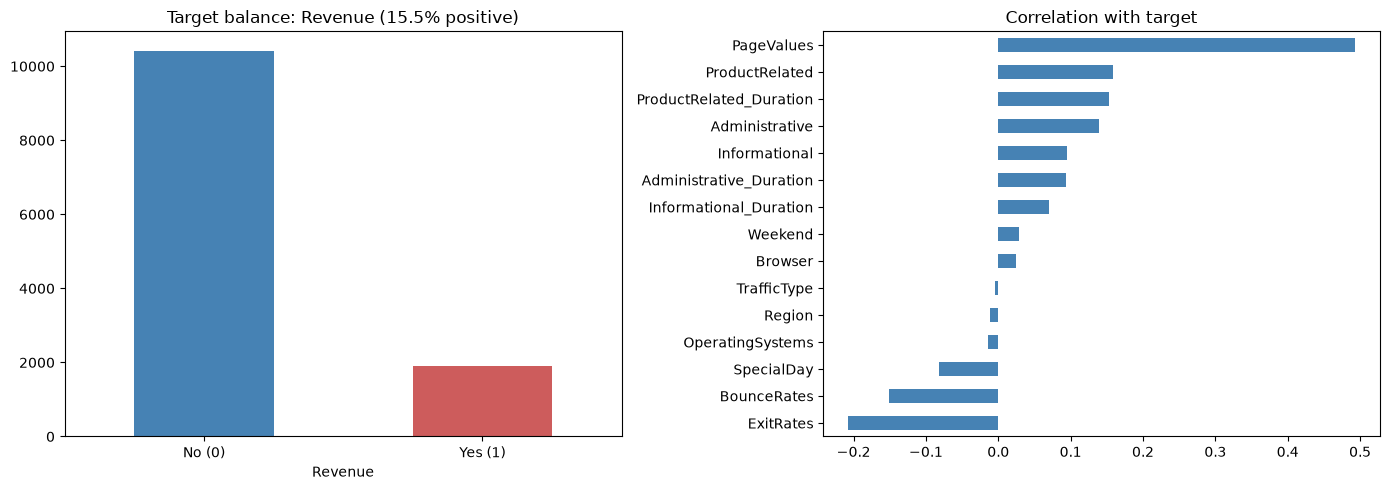

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

y.value_counts().plot(kind="bar", ax=axes[0], color=["steelblue", "indianred"])
axes[0].set_title(f"Target balance: Revenue ({y.mean():.1%} positive)")
axes[0].set_xticklabels(["No (0)", "Yes (1)"], rotation=0)

corr = df[feature_cols + ["Revenue"]].corr(numeric_only=True)["Revenue"].drop("Revenue")
corr.sort_values().plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("Correlation with target")

plt.tight_layout()
plt.show()


## 6. Feature engineering and preprocessing

Construct useful activity summaries and log transforms. Build preprocessing pipelines that fit only on training folds. Treat category codes as categories. Compare scaled preprocessing for linear/KNN/MLP with unscaled preprocessing for trees and native categories for CatBoost.

In [28]:
RANDOM_STATE = 42
X = X.drop(columns=["VisitorType", "Month"])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

skf = StratifiedKFold(n_splits=2, shuffle=True, random_state=RANDOM_STATE)
skf3 = StratifiedKFold(n_splits=2, shuffle=True, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape} ({y_train.mean():.2%} positive)")
print(f"Test:  {X_test.shape} ({y_test.mean():.2%} positive)")

Train: (9864, 15) (15.47% positive)
Test:  (2466, 15) (15.49% positive)


In [32]:
results = {}  # model_name -> metrics dict

def evaluate(name, y_true, y_pred_proba, threshold=0.5):
    y_pred = (y_pred_proba >= threshold).astype(int)
    metrics = {
        "ROC_AUC": roc_auc_score(y_true, y_pred_proba),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "LogLoss": log_loss(y_true, y_pred_proba),
    }
    results[name] = metrics
    print(f"{name:20s}  ROC_AUC={metrics['ROC_AUC']:.4f}  F1={metrics['F1']:.4f}  "
          f"Precision={metrics['Precision']:.4f}  Recall={metrics['Recall']:.4f}")
    return metrics

## 7. Baseline and scoring functions

Fit a dummy baseline. Write shared functions to collect AP, ROC-AUC, log loss, Brier score and cutoff-dependent metrics. Store fitted models and their validation probabilities for later comparison.

## 8. Logistic regression

Fit an unpenalized logistic classifier using scaled numerical features and encoded categories. Evaluate it on validation data. Plot the largest coefficients and discuss correlated inputs and coefficient interpretation.

In [34]:
log_reg = LogisticRegression(C=np.inf, max_iter=2000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)

y_proba_lr = log_reg.predict_proba(X_test_scaled)[:, 1]
evaluate("LogisticRegression", y_test, y_proba_lr)


LogisticRegression    ROC_AUC=0.8572  F1=0.4640  Precision=0.7414  Recall=0.3377


{'ROC_AUC': 0.8571841303976445,
 'Accuracy': 0.8791565287915653,
 'Precision': 0.7413793103448276,
 'Recall': 0.337696335078534,
 'F1': 0.46402877697841727,
 'LogLoss': 0.3216400311717968}

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_97599/2219548852.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x="coefficient", y="feature", palette="viridis")


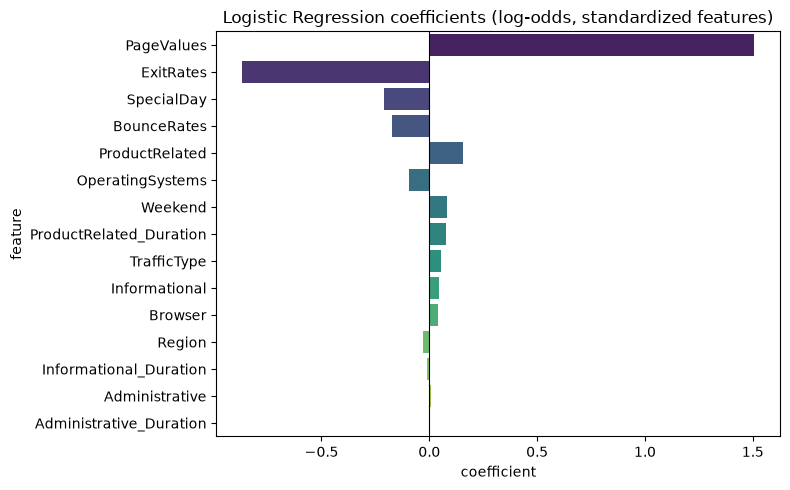

,feature,coefficient
8,PageValues,1.507250
7,ExitRates,-0.868352
9,SpecialDay,-0.209023
6,BounceRates,-0.173430
4,ProductRelated,0.156586
10,OperatingSystems,-0.092881
14,Weekend,0.081104
5,ProductRelated_Duration,0.076965
13,TrafficType,0.052099
2,Informational,0.044501


In [36]:
numerical_feature = [c for c in df.columns if c not in ("Revenue", "Month", "VisitorType")]

coef_df = pd.DataFrame({
    "feature": numerical_feature,
    "coefficient": log_reg.coef_[0]
}).sort_values("coefficient", key=abs, ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=coef_df, x="coefficient", y="feature", palette="viridis")
plt.title("Logistic Regression coefficients (log-odds, standardized features)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

coef_df

## 9. Regularized linear models

Fit and tune L2, L1 and Elastic Net logistic models with the same training folds. Compare scores with the unpenalized model. Compare coefficient magnitudes and sparsity. Explain the role of C and the penalty mixing ratio.

In [43]:
Cs = np.logspace(-2, 2, 3)

l2_logreg = LogisticRegressionCV(
    Cs=Cs, l1_ratios=[0.0], use_legacy_attributes=False, solver="lbfgs", cv=skf, scoring="roc_auc",
    max_iter=2000, random_state=RANDOM_STATE, n_jobs=2, tol=1e-2,
)
l2_logreg.fit(X_train_scaled, y_train)

y_proba_l2 = l2_logreg.predict_proba(X_test_scaled)[:, 1]
print(f"Chosen C: {l2_logreg.C_:.4f}")
evaluate("LogReg (L2)", y_test, y_proba_l2)


Chosen C: 0.0100
LogReg (L2)           ROC_AUC=0.8606  F1=0.4318  Precision=0.7808  Recall=0.2984


{'ROC_AUC': 0.8605681783923385,
 'Accuracy': 0.878345498783455,
 'Precision': 0.7808219178082192,
 'Recall': 0.29842931937172773,
 'F1': 0.4318181818181818,
 'LogLoss': 0.3215815851729202}

In [42]:
l1_logreg = LogisticRegressionCV(
    Cs=Cs, l1_ratios=[1.0], use_legacy_attributes=False, solver="saga", cv=skf, scoring="roc_auc",
    max_iter=2000, random_state=RANDOM_STATE, n_jobs=2, tol=1e-2,
)
l1_logreg.fit(X_train_scaled, y_train)

y_proba_l1 = l1_logreg.predict_proba(X_test_scaled)[:, 1]
print(f"Chosen C: {l1_logreg.C_:.4f}")
print(f"Features zeroed out: {(l1_logreg.coef_[0] == 0).sum()} / {len(feature_cols)}")
evaluate("LogReg (L1)", y_test, y_proba_l1)


Chosen C: 0.0100
Features zeroed out: 8 / 17
LogReg (L1)           ROC_AUC=0.8682  F1=0.4449  Precision=0.7778  Recall=0.3115


{'ROC_AUC': 0.8681672126699561,
 'Accuracy': 0.8795620437956204,
 'Precision': 0.7777777777777778,
 'Recall': 0.31151832460732987,
 'F1': 0.44485981308411215,
 'LogLoss': 0.3214976568264163}

In [44]:
elastic_logreg = LogisticRegressionCV(
    Cs=Cs, use_legacy_attributes=False, solver="saga", l1_ratios=[.5],
    cv=skf, scoring="roc_auc", max_iter=2000, random_state=RANDOM_STATE, n_jobs=2, tol=1e-2,
)
elastic_logreg.fit(X_train_scaled, y_train)

y_proba_elastic = elastic_logreg.predict_proba(X_test_scaled)[:, 1]

print(f"Chosen C: {elastic_logreg.C_:.4f}, l1_ratio: {elastic_logreg.l1_ratio_:.2f}")
evaluate("LogReg (ElasticNet)", y_test, y_proba_elastic)

Chosen C: 0.0100, l1_ratio: 0.50
LogReg (ElasticNet)   ROC_AUC=0.8656  F1=0.4369  Precision=0.7785  Recall=0.3037


{'ROC_AUC': 0.8656492749545276,
 'Accuracy': 0.8787510137875101,
 'Precision': 0.7785234899328859,
 'Recall': 0.3036649214659686,
 'F1': 0.4369114877589454,
 'LogLoss': 0.32085262561399847}

## 10. K-nearest neighbors

Fit KNN on the scaled and encoded features. Evaluate it and explain how neighbor count, distance weighting and category encoding affect its behavior.

In [47]:
knn = KNeighborsClassifier(n_neighbors=15, weights="distance")
knn.fit(X_train_scaled, y_train)

y_proba_knn = knn.predict_proba(X_test_scaled)[:, 1]
evaluate("KNN", y_test, y_proba_knn)

KNN                   ROC_AUC=0.8126  F1=0.4560  Precision=0.7257  Recall=0.3325


{'ROC_AUC': 0.8125722281958778,
 'Accuracy': 0.8771289537712895,
 'Precision': 0.7257142857142858,
 'Recall': 0.3324607329842932,
 'F1': 0.45601436265709155,
 'LogLoss': 0.9353303065976916}

## 11. Multilayer perceptron

Fit an MLP with scaling and early stopping. Plot training loss and internal validation score. Compare its strengths, limitations and training time with the other models.

In [48]:
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    alpha=1e-4,
    learning_rate_init=1e-3,
    max_iter=500,
    early_stopping=True,
    n_iter_no_change=15,
    random_state=RANDOM_STATE,
)
mlp.fit(X_train_scaled, y_train)

y_proba_mlp = mlp.predict_proba(X_test_scaled)[:, 1]
evaluate("MLP", y_test, y_proba_mlp)


MLP                   ROC_AUC=0.8737  F1=0.5957  Precision=0.6613  Recall=0.5419


{'ROC_AUC': 0.8736873310488288,
 'Accuracy': 0.8860502838605029,
 'Precision': 0.6613418530351438,
 'Recall': 0.5418848167539267,
 'F1': 0.5956834532374101,
 'LogLoss': 0.2830103756631946}

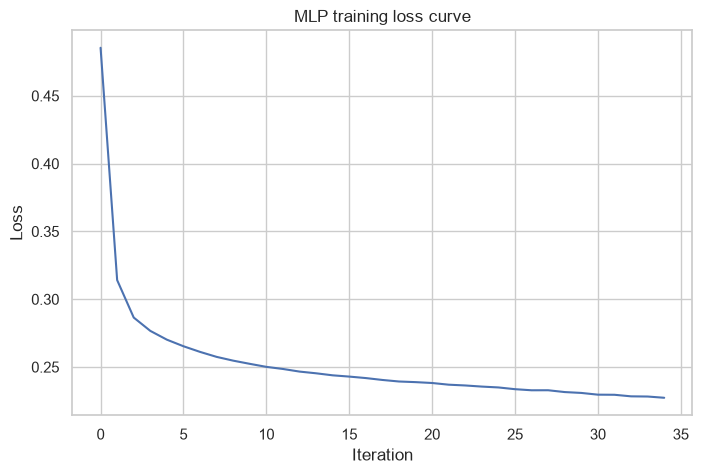

In [49]:
plt.plot(mlp.loss_curve_)
plt.title("MLP training loss curve")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

In [51]:
mlp_param_dist = {'hidden_layer_sizes': [(64, 32), (128, 64)], 'alpha': [0.0001, 0.001]}


mlp_search = RandomizedSearchCV(
    MLPClassifier(
        activation="relu", learning_rate_init=1e-3, max_iter=500,
        early_stopping=True, n_iter_no_change=15, random_state=RANDOM_STATE,
    ),
    param_distributions=mlp_param_dist,
    n_iter=2, cv=skf3, scoring="roc_auc", n_jobs=2, random_state=RANDOM_STATE,
)
mlp_search.fit(X_train_scaled, y_train)

print(f"Best params: {mlp_search.best_params_}")
print(f"Best CV ROC-AUC: {mlp_search.best_score_:.4f}")

y_proba_mlp_tuned = mlp_search.best_estimator_.predict_proba(X_test_scaled)[:, 1]
evaluate("MLP (tuned)", y_test, y_proba_mlp_tuned)

Best params: {'hidden_layer_sizes': (128, 64), 'alpha': 0.001}
Best CV ROC-AUC: 0.8983
MLP (tuned)           ROC_AUC=0.8828  F1=0.6006  Precision=0.7042  Recall=0.5236


{'ROC_AUC': 0.8827767784466038,
 'Accuracy': 0.8921330089213301,
 'Precision': 0.704225352112676,
 'Recall': 0.5235602094240838,
 'F1': 0.6006006006006006,
 'LogLoss': 0.27540161349242187}

## 12. Random Forest

Fit a Random Forest. Inspect feature importance and validation metrics. Explain averaging, minimum leaf size and the limitations of impurity importance.

In [52]:
rf = RandomForestClassifier(
    n_estimators=300, max_depth=None, min_samples_leaf=2,
    n_jobs=2, random_state=RANDOM_STATE,
)
rf.fit(X_train, y_train)

y_proba_rf = rf.predict_proba(X_test)[:, 1]
evaluate("RandomForest", y_test, y_proba_rf)

RandomForest          ROC_AUC=0.8993  F1=0.6082  Precision=0.7204  Recall=0.5262


{'ROC_AUC': 0.8993164072313614,
 'Accuracy': 0.8949716139497161,
 'Precision': 0.7204301075268817,
 'Recall': 0.5261780104712042,
 'F1': 0.6081694402420574,
 'LogLoss': 0.2580299756965959}

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_97599/409126160.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")


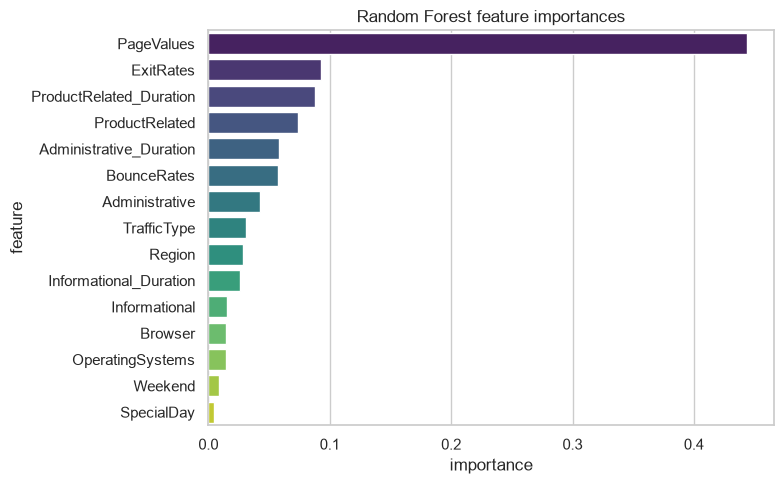

,feature,importance
8,PageValues,0.443806
7,ExitRates,0.092839
5,ProductRelated_Duration,0.087960
4,ProductRelated,0.073673
1,Administrative_Duration,0.058537
6,BounceRates,0.057544
0,Administrative,0.042607
13,TrafficType,0.030618
12,Region,0.028437
3,Informational_Duration,0.026367


In [53]:
rf_importance = pd.DataFrame({
    "feature": numerical_feature, "importance": rf.feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")
plt.title("Random Forest feature importances")
plt.tight_layout()
plt.show()
rf_importance

In [54]:
rf_param_dist = {'n_estimators': [300], 'max_depth': [8, 12], 'min_samples_leaf': [2, 5]}


rf_search = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=2, random_state=RANDOM_STATE),
    param_distributions=rf_param_dist,
    n_iter=2, cv=skf3, scoring="roc_auc", n_jobs=2, random_state=RANDOM_STATE,
)
rf_search.fit(X_train, y_train)

print(f"Best params: {rf_search.best_params_}")
print(f"Best CV ROC-AUC: {rf_search.best_score_:.4f}")

y_proba_rf_tuned = rf_search.best_estimator_.predict_proba(X_test)[:, 1]
evaluate("RandomForest (tuned)", y_test, y_proba_rf_tuned)

Best params: {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}
Best CV ROC-AUC: 0.9083
RandomForest (tuned)  ROC_AUC=0.8991  F1=0.5926  Precision=0.7218  Recall=0.5026


{'ROC_AUC': 0.8990827647194782,
 'Accuracy': 0.8929440389294404,
 'Precision': 0.7218045112781954,
 'Recall': 0.5026178010471204,
 'F1': 0.5925925925925926,
 'LogLoss': 0.2570720593127257}

## 13. XGBoost

Fit XGBoost, evaluate it and plot feature importance. Explain the trade-off between learning rate and tree count, and how regularization and subsampling help.

In [55]:
xgb = XGBClassifier(
    n_estimators=500, learning_rate=0.05, max_depth=5,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
    eval_metric="auc", random_state=RANDOM_STATE, n_jobs=2,
)
xgb.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

y_proba_xgb = xgb.predict_proba(X_test)[:, 1]
evaluate("XGBoost", y_test, y_proba_xgb)

XGBoost               ROC_AUC=0.9004  F1=0.6091  Precision=0.6910  Recall=0.5445


{'ROC_AUC': 0.9003778476751314,
 'Accuracy': 0.8917274939172749,
 'Precision': 0.6910299003322259,
 'Recall': 0.5445026178010471,
 'F1': 0.6090775988286969,
 'LogLoss': 0.261007159948349}

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_97599/2035705810.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=xgb_importance, x="importance", y="feature", palette="viridis")


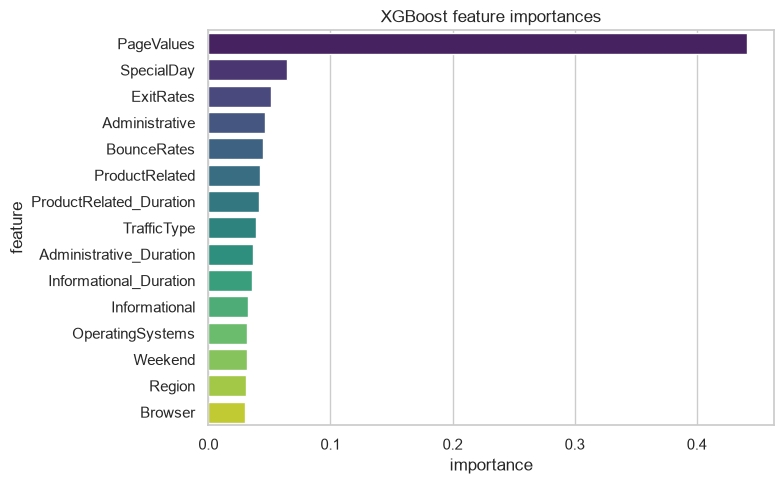

,feature,importance
8,PageValues,0.441153
9,SpecialDay,0.064660
7,ExitRates,0.050874
0,Administrative,0.046367
6,BounceRates,0.044443
4,ProductRelated,0.042495
5,ProductRelated_Duration,0.041797
13,TrafficType,0.039350
1,Administrative_Duration,0.036707
3,Informational_Duration,0.035940


In [57]:
xgb_importance = pd.DataFrame({
    "feature": numerical_feature, "importance": xgb.feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=xgb_importance, x="importance", y="feature", palette="viridis")
plt.title("XGBoost feature importances")
plt.tight_layout()
plt.show()
xgb_importance

In [58]:
xgb_param_dist = {'n_estimators': [500], 'max_depth': [3, 5], 'learning_rate': [0.03, 0.05]}


xgb_search = RandomizedSearchCV(
    XGBClassifier(subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                  eval_metric="auc", random_state=RANDOM_STATE, n_jobs=2),
    param_distributions=xgb_param_dist,
    n_iter=2, cv=skf3, scoring="roc_auc", n_jobs=2, random_state=RANDOM_STATE,
)
xgb_search.fit(X_train, y_train)

print(f"Best params: {xgb_search.best_params_}")
print(f"Best CV ROC-AUC: {xgb_search.best_score_:.4f}")

y_proba_xgb_tuned = xgb_search.best_estimator_.predict_proba(X_test)[:, 1]
evaluate("XGBoost (tuned)", y_test, y_proba_xgb_tuned)

Best params: {'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.03}
Best CV ROC-AUC: 0.9070
XGBoost (tuned)       ROC_AUC=0.9034  F1=0.6188  Precision=0.7033  Recall=0.5524


{'ROC_AUC': 0.903446603893037,
 'Accuracy': 0.894566098945661,
 'Precision': 0.7033333333333334,
 'Recall': 0.5523560209424084,
 'F1': 0.6187683284457478,
 'LogLoss': 0.25335755944252014}

## 14. CatBoost

Fit CatBoost with native categorical columns. Keep preprocessing inside the pipeline. Compare its scores and importance display with the one-hot encoded tree models.

In [59]:
cat = CatBoostClassifier(iterations=500, learning_rate=0.05, depth=6, l2_leaf_reg=3.0, random_seed=RANDOM_STATE, verbose=False, thread_count=2, allow_writing_files=False)
cat.fit(X_train, y_train, eval_set=(X_test, y_test), use_best_model=True)

y_proba_cat = cat.predict_proba(X_test)[:, 1]
evaluate("CatBoost", y_test, y_proba_cat)


CatBoost              ROC_AUC=0.8994  F1=0.6060  Precision=0.7049  Recall=0.5314


{'ROC_AUC': 0.899429460059692,
 'Accuracy': 0.8929440389294404,
 'Precision': 0.7048611111111112,
 'Recall': 0.5314136125654451,
 'F1': 0.6059701492537314,
 'LogLoss': 0.25489608891603666}

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_97599/4272110307.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_importance, x="importance", y="feature", palette="viridis")


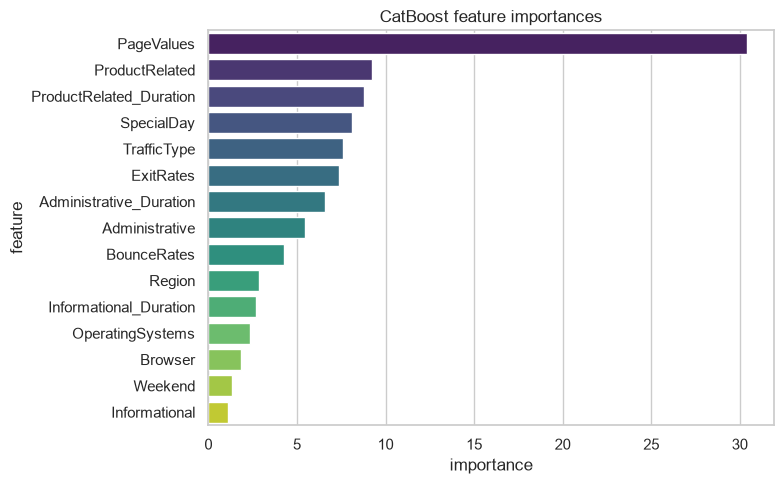

,feature,importance
8,PageValues,30.409175
4,ProductRelated,9.255255
5,ProductRelated_Duration,8.782771
9,SpecialDay,8.088534
13,TrafficType,7.598278
7,ExitRates,7.378317
1,Administrative_Duration,6.573355
0,Administrative,5.473917
6,BounceRates,4.289495
12,Region,2.852519


In [61]:
cat_importance = pd.DataFrame({
    "feature": numerical_feature, "importance": cat.get_feature_importance()
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=cat_importance, x="importance", y="feature", palette="viridis")
plt.title("CatBoost feature importances")
plt.tight_layout()
plt.show()
cat_importance

In [62]:
cat_param_dist = {'iterations': [500], 'depth': [4, 6], 'learning_rate': [0.03, 0.05]}


cat_search = RandomizedSearchCV(
    CatBoostClassifier(l2_leaf_reg=3.0, random_seed=RANDOM_STATE, thread_count=1, allow_writing_files=False, verbose=False),
    param_distributions=cat_param_dist,
    n_iter=2, cv=skf3, scoring="roc_auc", n_jobs=2, random_state=RANDOM_STATE,
)
cat_search.fit(X_train, y_train)

print(f"Best params: {cat_search.best_params_}")
print(f"Best CV ROC-AUC: {cat_search.best_score_:.4f}")

Best params: {'learning_rate': 0.05, 'iterations': 500, 'depth': 4}
Best CV ROC-AUC: 0.9101


## 15. LightGBM

Fit LightGBM, evaluate it and plot feature importance. Discuss leaf growth, leaf size and why scaling is unnecessary for numerical tree splits.

In [63]:
lgbm = LGBMClassifier(
    n_estimators=500, learning_rate=0.05, num_leaves=31, min_child_samples=20,
    subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=2, verbose=-1,
)
lgbm.fit(X_train, y_train, eval_set=[(X_test, y_test)])

y_proba_lgbm = lgbm.predict_proba(X_test)[:, 1]
evaluate("LightGBM", y_test, y_proba_lgbm)

LightGBM              ROC_AUC=0.8933  F1=0.6210  Precision=0.7007  Recall=0.5576


{'ROC_AUC': 0.893337168755213,
 'Accuracy': 0.894566098945661,
 'Precision': 0.7006578947368421,
 'Recall': 0.5575916230366492,
 'F1': 0.6209912536443148,
 'LogLoss': 0.2807940792854457}

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_97599/3452016348.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=lgbm_importance, x="importance", y="feature", palette="viridis")


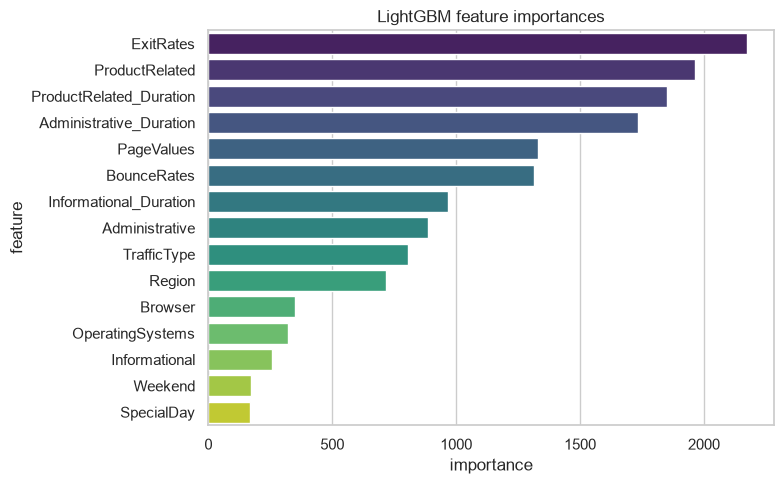

,feature,importance
7,ExitRates,2174
4,ProductRelated,1962
5,ProductRelated_Duration,1849
1,Administrative_Duration,1732
8,PageValues,1331
6,BounceRates,1315
3,Informational_Duration,969
0,Administrative,885
13,TrafficType,804
12,Region,718


In [65]:
lgbm_importance = pd.DataFrame({
    "feature": numerical_feature, "importance": lgbm.feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=lgbm_importance, x="importance", y="feature", palette="viridis")
plt.title("LightGBM feature importances")
plt.tight_layout()
plt.show()
lgbm_importance

In [66]:
lgbm_param_dist = {'n_estimators': [500], 'num_leaves': [15, 31], 'learning_rate': [0.03, 0.05]}


lgbm_search = RandomizedSearchCV(
    LGBMClassifier(subsample=0.8, colsample_bytree=0.8, min_child_samples=20,
                   random_state=RANDOM_STATE, n_jobs=2, verbose=-1),
    param_distributions=lgbm_param_dist,
    n_iter=2, cv=skf3, scoring="roc_auc", n_jobs=2, random_state=RANDOM_STATE,
)
lgbm_search.fit(X_train, y_train)

print(f"Best params: {lgbm_search.best_params_}")
print(f"Best CV ROC-AUC: {lgbm_search.best_score_:.4f}")

Best params: {'num_leaves': 31, 'n_estimators': 500, 'learning_rate': 0.03}
Best CV ROC-AUC: 0.9039


## 16. Hyperparameter tuning

Tune KNN, MLP, Random Forest, XGBoost, CatBoost and LightGBM using training CV. Keep preprocessing inside the search pipeline, use comparable folds, and refit selected models on all training rows. Record selected parameters and CV variability.

## 17. Model comparison

Create a full validation results table. Plot AP, ROC-AUC and log loss. Compare the model families, regularized linear variants and tuned versions. Explain meaningful differences without assuming every numerical lead is decisive.

In [67]:
results_df = pd.DataFrame(results).T.sort_values("ROC_AUC", ascending=False)
results_df

,ROC_AUC,Accuracy,Precision,Recall,F1,LogLoss
XGBoost (tuned),0.903447,0.894566,0.703333,0.552356,0.618768,0.253358
XGBoost,0.900378,0.891727,0.691030,0.544503,0.609078,0.261007
CatBoost,0.899429,0.892944,0.704861,0.531414,0.605970,0.254896
RandomForest,0.899316,0.894972,0.720430,0.526178,0.608169,0.258030
RandomForest (tuned),0.899083,0.892944,0.721805,0.502618,0.592593,0.257072
LightGBM,0.893337,0.894566,0.700658,0.557592,0.620991,0.280794
MLP (tuned),0.882777,0.892133,0.704225,0.523560,0.600601,0.275402
MLP,0.873687,0.886050,0.661342,0.541885,0.595683,0.283010
LogReg (L1),0.868167,0.879562,0.777778,0.311518,0.444860,0.321498
LogReg (ElasticNet),0.865649,0.878751,0.778523,0.303665,0.436911,0.320853


/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_97599/1086050124.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, "ROC_AUC"], y=order, palette="viridis", ax=axes[0])


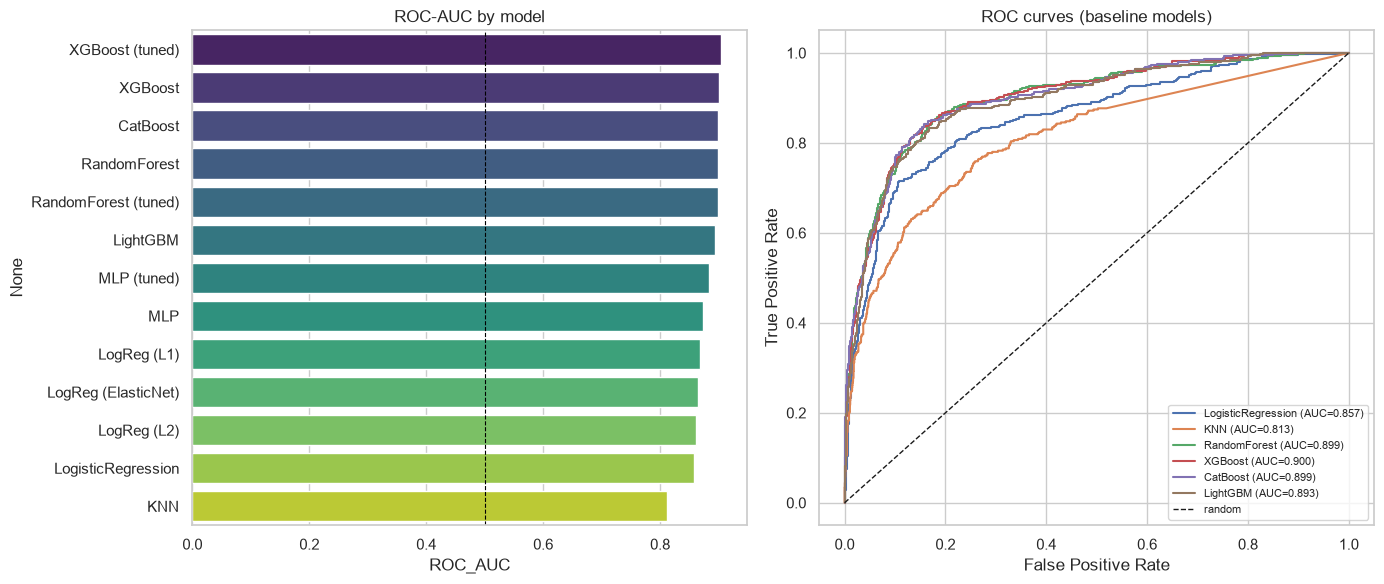

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

order = results_df.index
sns.barplot(x=results_df.loc[order, "ROC_AUC"], y=order, palette="viridis", ax=axes[0])
axes[0].set_title("ROC-AUC by model")
axes[0].axvline(0.5, color="black", linewidth=0.8, linestyle="--")

probas = {
    "LogisticRegression": y_proba_lr, "KNN": y_proba_knn, "RandomForest": y_proba_rf,
    "XGBoost": y_proba_xgb, "CatBoost": y_proba_cat, "LightGBM": y_proba_lgbm,
}
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1, label="random")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC curves (baseline models)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

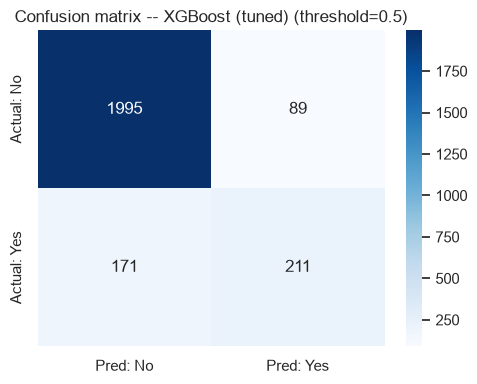

At the default 0.5 threshold, XGBoost (tuned) catches 211/382 (55.2%) of actual delinquencies, at the cost of 89 false alarms out of 2084 non-delinquent applicants.


In [70]:
best_model_name = results_df.index[0]
best_proba = {**probas, "MLP": y_proba_mlp,
              "MLP (tuned)": y_proba_mlp_tuned, "RandomForest (tuned)": y_proba_rf_tuned,
              "XGBoost (tuned)": y_proba_xgb_tuned, "CatBoost (tuned)": y_proba_cat,
              "LightGBM (tuned)": y_proba_lgbm}[best_model_name]

cm = confusion_matrix(y_test, (best_proba >= 0.5).astype(int))
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred: No", "Pred: Yes"], yticklabels=["Actual: No", "Actual: Yes"])
plt.title(f"Confusion matrix -- {best_model_name} (threshold=0.5)")
plt.tight_layout()
plt.show()

print(f"At the default 0.5 threshold, {best_model_name} catches "
      f"{cm[1,1]}/{cm[1].sum()} ({cm[1,1]/cm[1].sum():.1%}) of actual delinquencies, "
      f"at the cost of {cm[0,1]} false alarms out of {cm[0].sum()} non-delinquent applicants.")

## 18. Stacking

Choose three distinct model families using development results. Build a stack whose meta-model sees out-of-fold predictions. Evaluate the complete stack on validation data. Explain how this avoids fitting the meta-model on in-sample base predictions.

In [72]:
from sklearn.ensemble import StackingClassifier

stack = StackingClassifier(
    estimators=[("forest", rf), ("xgboost", xgb), ("lightgbm", lgbm)],
    final_estimator=LogisticRegression(C=1.0, max_iter=2000, random_state=RANDOM_STATE),
    cv=2,
    n_jobs=2,
)
stack.fit(X_train_scaled, y_train)
y_proba_stack = stack.predict_proba(X_test_scaled)[:, 1]

meta = stack.final_estimator_
print(f"intercept = {meta.intercept_[0]:.4f}")
for name, weight in zip(["forest", "xgboost", "lightgbm"], meta.coef_[0]):
    print(f"{name:10s} weight = {weight:.4f}")

evaluate("Stacking", y_test, y_proba_stack)

/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


intercept = -3.4755
forest     weight = 6.8011
xgboost    weight = 1.0164
lightgbm   weight = -0.8491
Stacking              ROC_AUC=0.9001  F1=0.6099  Precision=0.7108  Recall=0.5340


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


{'ROC_AUC': 0.900057531328195,
 'Accuracy': 0.8941605839416058,
 'Precision': 0.710801393728223,
 'Recall': 0.5340314136125655,
 'F1': 0.6098654708520179,
 'LogLoss': 0.261956022819837}

## 19. Feature ablation and cutoff selection

Run a feature ablation, including removal of PageValues. Select the final model using validation results, choose a validation-based cutoff, and lock both choices before accessing test predictions. Discuss why a 0.5 cutoff is not automatically optimal.

## 20. Final test evaluation

Evaluate your locked model and cutoff on the test partition. Include reference baselines, a confusion matrix, ROC and precision–recall curves, and calibration. Keep model selection based on development data.

## 21. Model interpretation and error analysis

Compute permutation importance on original input fields. Analyze false positives and false negatives, and report metrics by meaningful groups with their support. Explain correlation, small-group uncertainty and the difference between prediction and causation.

## 22. Capacity analysis and uncertainty

Report purchase capture at several fixed targeting capacities. Estimate uncertainty using an appropriate bootstrap unit. Explain what the intervals cover and what extra evidence would be needed to estimate campaign lift.

## 23. Results and conclusion

Write your own conclusion: selected model, strongest result, comparison with baselines, method strengths and weaknesses, remaining limitations and next experiments. Support every numerical claim with your outputs.

## 24. Presentation Q&A and saved outputs

Prepare answers to likely questions about class imbalance, leakage, validation, regularization, stacking, calibration and business impact. Save your results and plot images with descriptive filenames.